# Predict 2D co-accessibility map and 1D accessibility track

This notebook takes a **2,048 bp genomic window** and produces:

1. **ChAI-Net prediction**: a predicted 2D co-accessibility map (128 x 128 bins, 16 bp per bin)
2. **Average accessibility prediction**: a predicted 1D accessibility track (128 bins, 16 bp per bin)

Only predictions are plotted (no observed targets).

## Requirements

- Python 3.8+ with `tensorflow`, `numpy`, `scipy`, `matplotlib`, `seaborn`, `pysam`
- [Basenji](https://github.com/calico/basenji) installed (provides `basenji.seqnn` and `basenji.dna_io`)
- ChAI-Net model files (parameters `.json` + weights `.h5`) for both the 2D model and the average accessibility model
- A reference genome FASTA (mm10), indexed with `samtools faidx mm10.fa` (creates `mm10.fa.fai` next to the FASTA)

Edit the **Configuration** cell below: set the file paths and the genomic window (`CHROM`, `START`).



## 1. Configuration 

In [4]:
# ---------------- Model files ----------------
CHAI_PARAMS = "models/ChAI_Net_params.json"
CHAI_WEIGHTS = "models/ChAI_Net_model_weights.h5"
AVG_PARAMS = "models/average_accessibility_model_params.json"
AVG_WEIGHTS = "models/average_accessibility_model_weights.h5"

# ---------------- Reference genome (indexed FASTA) ----------------
GENOME_FASTA = "mm10_genome/mm10_genome.fa" # download from http://hgdownload.cse.ucsc.edu/goldenPath/mm10/bigZips/

# ---------------- Genomic window to predict ----------------
CHROM = "chr2"
START = 27426432          # 0-based start; END is START + 2048

# ---------------- Plot options ----------------
SMOOTH_SIZE = 10          # smoothing window (in bins) for the 1D track; 1 = no smoothing
MAP_VMIN, MAP_VMAX = -0.2, 0.8   # color scale of the 2D map
TRACK_YLIM = (0, 1)       # y-axis range of the 1D track

# ---------------- Hardware ----------------
USE_GPU = False           # False = run on CPU (fast enough for a single window)

## 2. Imports and helper functions

In [5]:
import os
if not USE_GPU:
    os.environ["CUDA_VISIBLE_DEVICES"] = "-1"   # must be set before importing tensorflow

import json

import matplotlib.pyplot as plt
import numpy as np
import pysam
import seaborn as sns
import tensorflow as tf
from basenji import dna_io, seqnn
from scipy.ndimage import uniform_filter1d
from scipy.spatial.distance import squareform

SEQ_LEN = 2048                  # model input length (bp)
N_BINS = 128                    # bins per side of the 2D map / length of the 1D track
BIN_SIZE = SEQ_LEN // N_BINS    # 16 bp per bin


def load_model(params_path, weights_path):
    """Build a Basenji SeqNN model from a params JSON and load its weights."""
    with open(params_path) as f:
        params_model = json.load(f)["model"]
    model = seqnn.SeqNN(params_model)
    model.restore(weights_path)
    return model


def fetch_one_hot(fasta_path, chrom, start, length=SEQ_LEN):
    """Fetch `length` bp from the genome and return it one-hot encoded, shape (length, 4)."""
    with pysam.Fastafile(fasta_path) as fasta:
        if chrom not in fasta.references:
            raise ValueError(f"{chrom} not found in {fasta_path}")
        if start < 0 or start + length > fasta.get_reference_length(chrom):
            raise ValueError(f"{chrom}:{start}-{start + length} falls outside the chromosome")
        seq = fasta.fetch(chrom, start, start + length).upper()
    return dna_io.dna_1hot(seq)


def predict(model, seq_1hot):
    """Run a model on a single one-hot sequence and return a flat numpy vector."""
    return model.model.predict(np.expand_dims(seq_1hot, 0), verbose=0).reshape(-1)


def vector_to_map(vec):
    """Convert the model's upper-triangle vector (8128,) into a symmetric 128x128 matrix.
    The main diagonal is not predicted, so it is set to NaN (shown blank)."""
    mat = squareform(vec).astype(float)
    np.fill_diagonal(mat, np.nan)
    return mat


def plot_prediction(map_vec, track_vec, chrom, start,
                    smooth_size=10, vmin=-0.2, vmax=0.8, track_ylim=(0, 1)):
    """2D predicted map on top, 1D predicted track underneath (x-axes aligned)."""
    mat = vector_to_map(map_vec)
    track = uniform_filter1d(np.asarray(track_vec).squeeze(), size=smooth_size)

    fig = plt.figure(figsize=(7, 8))
    gs = fig.add_gridspec(2, 2, height_ratios=[6, 1.2], width_ratios=[1, 0.04],
                          hspace=0.05, wspace=0.04)
    ax_map = fig.add_subplot(gs[0, 0])
    ax_cbar = fig.add_subplot(gs[0, 1])
    ax_trk = fig.add_subplot(gs[1, 0])

    # 2D map
    sns.heatmap(mat, cmap="coolwarm", vmin=vmin, vmax=vmax,
                cbar=True, cbar_ax=ax_cbar, ax=ax_map)
    ax_map.set_xticks([])
    ax_map.set_yticks([])
    ax_map.set_title(f"ChAI-Net prediction  {chrom}:{start:,}-{start + SEQ_LEN:,}", fontsize=13)

    # 1D track, x-range matched to the heatmap (+0.5 centers points on heatmap cells)
    ax_trk.plot(np.arange(len(track)) + 0.5, track, color="black")
    ax_trk.set_xlim(0, mat.shape[0])
    ax_trk.set_ylim(*track_ylim)
    ax_trk.set_xticks([0, N_BINS / 2, N_BINS])
    ax_trk.set_xticklabels([f"{start:,}", f"{start + SEQ_LEN // 2:,}", f"{start + SEQ_LEN:,}"])
    ax_trk.set_xlabel(chrom)
    ax_trk.set_ylabel("Accessibility")
    ax_trk.tick_params(axis="both", labelsize=11)
    return fig

## 3. Load the models

In [6]:
chai_model = load_model(CHAI_PARAMS, CHAI_WEIGHTS)
avg_model = load_model(AVG_PARAMS, AVG_WEIGHTS)
print("Models loaded.")

2026-10-26 11:23:12.509665: W tensorflow/stream_executor/platform/default/dso_loader.cc:64] Could not load dynamic library 'libcuda.so.1'; dlerror: libcuda.so.1: cannot open shared object file: No such file or directory
2026-10-26 11:23:12.509690: W tensorflow/stream_executor/cuda/cuda_driver.cc:269] failed call to cuInit: UNKNOWN ERROR (303)
2026-10-26 11:23:12.509706: I tensorflow/stream_executor/cuda/cuda_diagnostics.cc:156] kernel driver does not appear to be running on this host (bueno.gladstone.internal): /proc/driver/nvidia/version does not exist
2026-10-26 11:23:12.509878: I tensorflow/core/platform/cpu_feature_guard.cc:193] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


Model: "model_1"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 sequence (InputLayer)          [(None, 2048, 4)]    0           []                               
                                                                                                  
 stochastic_reverse_complement   ((None, 2048, 4),   0           ['sequence[0][0]']               
 (StochasticReverseComplement)   ())                                                              
                                                                                                  
 stochastic_shift (StochasticSh  (None, 2048, 4)     0           ['stochastic_reverse_complement[0
 ift)                                                            ][0]']                           
                                                                                            

## 4. Predict

Extracts the sequence for `CHROM:START-(START+2048)` and runs both models. Expected output shapes:

- 2D map vector: `(8128,)` — the upper triangle of a 128 x 128 map
- 1D track: `(128,)`

In [7]:
seq_1hot = fetch_one_hot(GENOME_FASTA, CHROM, START)

chai_pred = predict(chai_model, seq_1hot)   # (8128,)
avg_pred = predict(avg_model, seq_1hot)     # (128,)
print("2D prediction:", chai_pred.shape, "| 1D prediction:", avg_pred.shape)

2D prediction: (8128,) | 1D prediction: (128,)


## 5. Plot

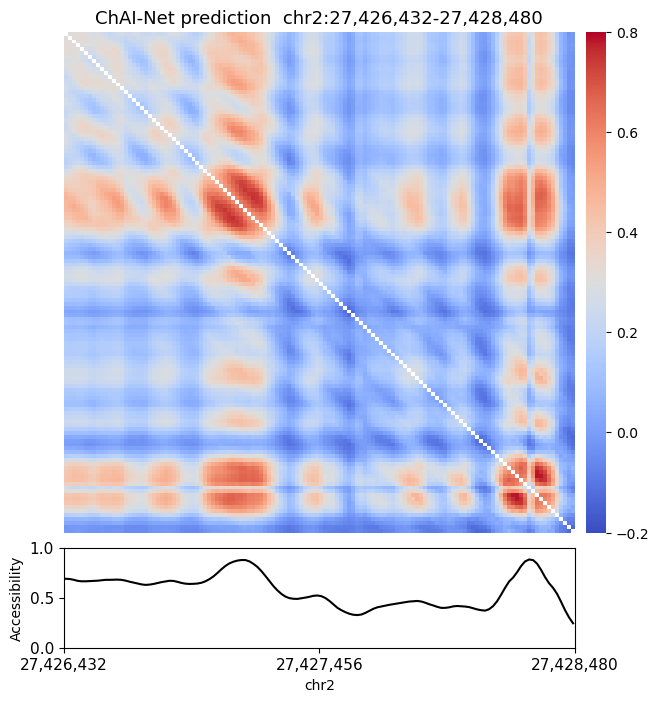

In [9]:
fig = plot_prediction(chai_pred, avg_pred, CHROM, START,
                      smooth_size=SMOOTH_SIZE, vmin=MAP_VMIN, vmax=MAP_VMAX,
                      track_ylim=TRACK_YLIM)

plt.show()